# 03 · Known-orbit EKF
Compare angles only with angles plus angular rates using paired measurements and the same initial error.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/baseline.json").exists() and (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project checkout")
sys.path.insert(0, str(ROOT / "src"))
from halo_tracking.study import load_config
cfg = load_config(ROOT / "configs/baseline.json")
cfg["simulation"]["periods"] = 1.0


## Prior and noise
Edit baseline.json or cfg below. P0 describes rotating-state errors; acceleration is derived. No measurements of Gateway enter this estimator.

In [2]:
cfg["estimation"], cfg["measurement"]

Out[2]: 
({'initial_position_sigma_km': 1.0,
  'initial_velocity_sigma_km_s': 1e-05,
  'acceleration_psd_normalized': 0.0},
 {'angle_sigma_arcsec': 1.0,
  'angular_rate_sigma_arcsec_s': 0.01,
  'rate_source': 'independent',
  'covariance_override': None})


In [3]:
from halo_tracking.study import run_study, save_study, summary
result = run_study(cfg)
summary(result)

Out[3]: 
{'angles': {'position_rmse_km': 3.9980213092797947,
  'velocity_rmse_km_s': 0.00015273436242142625,
  'final_position_rss_sigma_km': 1.1459409434014676,
  'mean_nis': 3.933338863181331},
 'angles_rates': {'position_rmse_km': 3.9991718904052145,
  'velocity_rmse_km_s': 0.00015277479616689012,
  'final_position_rss_sigma_km': 1.1458913336875645,
  'mean_nis': 5.945729511992863}}


/workspace/scratch/678b6a3ef004/Halo_Orbit_Tracking/src/halo_tracking/study.py:52: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  result=make_truth(cfg); result['config']=cfg


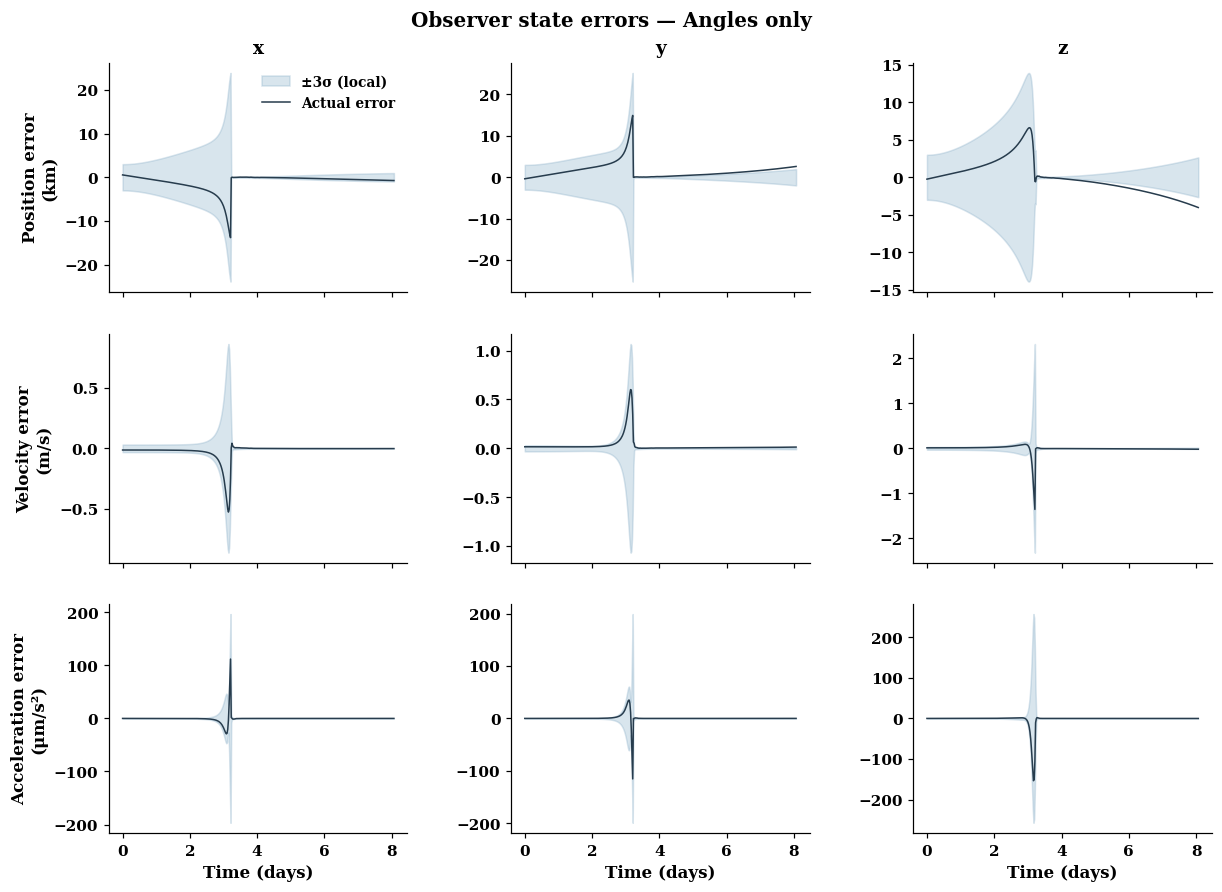

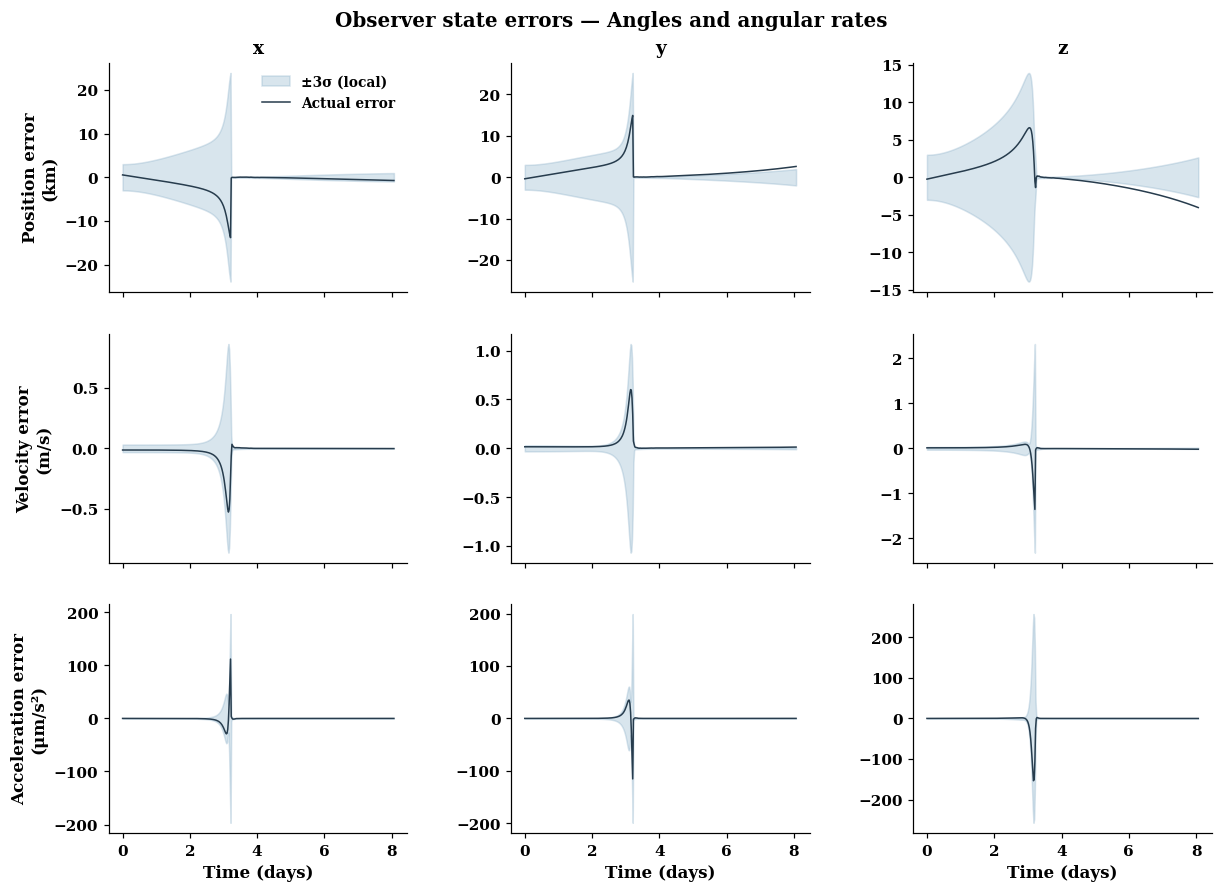

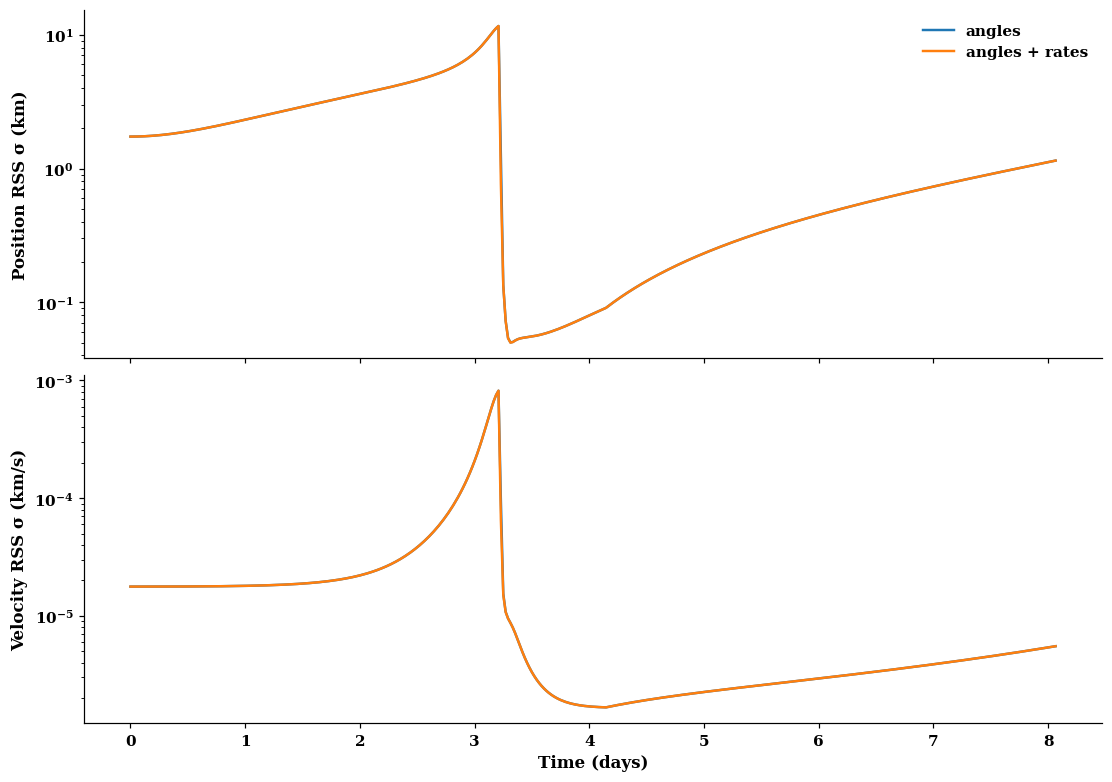

In [4]:
from halo_tracking.plotting import estimation_errors, uncertainty_comparison, export
fig_ao = estimation_errors(result, "angles")
fig_rates = estimation_errors(result, "angles_rates")
fig_compare = uncertainty_comparison(result)

Bounds are conditional on the CR3BP model, known site, measurement-noise assumptions and local linearization. One noise realization cannot establish covariance consistency.

In [5]:
save_study(result, ROOT / "results/estimation")
for name, fig in [("angles",fig_ao),("angles_rates",fig_rates),("comparison",fig_compare)]:
    export(fig, ROOT / "results/estimation/figures" / (name + ".png"))